# Ecuación de Calor 1D — Solución por Series de Fourier

## Planteamiento del problema

La **ecuación de calor 1D** (ecuación parabólica de difusión) en el dominio $x \in [0,1]$ es:

$$\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}$$

con condiciones de frontera de Dirichlet homogéneas:

$$u(0, t) = 0, \qquad u(1, t) = 0, \qquad \forall\, t > 0$$

y condición inicial:

$$u(x, 0) = \sin(2\pi x) + \frac{1}{3}\sin(4\pi x) + \frac{1}{5}\sin(6\pi x)$$

---

## Solución analítica por separación de variables

Proponemos $u(x,t) = X(x)\,T(t)$. Sustituyendo:

$$\frac{T'}{\alpha T} = \frac{X''}{X} = -\lambda^2$$

Las dos EDO resultantes son:

$$X'' + \lambda^2 X = 0 \quad \Rightarrow \quad X_n(x) = \sin(n\pi x), \quad n = 1,2,3,\ldots$$

$$T' + \alpha(n\pi)^2 T = 0 \quad \Rightarrow \quad T_n(t) = e^{-\alpha(n\pi)^2 t}$$

La solución general es la superposición:

$$\boxed{u(x,t) = \sum_{n=1}^{\infty} B_n\, e^{-\alpha(n\pi)^2 t}\, \sin(n\pi x)}$$

Los coeficientes $B_n$ se determinan con la condición inicial mediante la fórmula de Fourier-seno:

$$B_n = 2\int_0^1 u(x,0)\,\sin(n\pi x)\,dx$$

---

## Tiempo redefinido (parámetro adimensional)

Definimos el **tiempo adimensional**:

$$\tau = \alpha\,\pi^2\,t$$

Con esto, la solución queda:

$$u(x,\tau) = \sum_{n=1}^{N_{\max}} B_n\, e^{-n^2 \tau}\, \sin(n\pi x)$$

El factor $\alpha\pi^2$ absorbido en $\tau$ elimina explícitamente la constante de difusividad de la exponencial, haciendo la solución adimensional y más general.

---

## Valor de la difusividad térmica $\alpha$

El valor de $\alpha$ depende del material. Para este problema **sin material específico**, usamos el valor de referencia para el **acero inoxidable 304** (material ingenieril común):

$$\alpha = 4.2 \times 10^{-6} \text{ m}^2/\text{s}$$

Sin embargo, como usamos el tiempo redefinido $\tau = \alpha\pi^2 t$, **el valor de $\alpha$ solo afecta la escala de tiempo físico**, no la forma de la solución. En la gráfica trabajamos directamente con $\tau$.

---

## Coeficientes $B_n$ para la condición inicial dada

La condición inicial ya está expresada como combinación de senos de Fourier:

$$u(x,0) = 1\cdot\sin(2\pi x) + \frac{1}{3}\cdot\sin(4\pi x) + \frac{1}{5}\cdot\sin(6\pi x)$$

Comparando con la base $\{\sin(n\pi x)\}$, se identifican directamente:

| $n$ | $n\pi$ | $B_n$ |
|-----|--------|-------|
| 2   | $2\pi$ | $1$   |
| 4   | $4\pi$ | $1/3$ |
| 6   | $6\pi$ | $1/5$ |
| resto | — | $0$ |

**Conclusión:** la solución exacta se alcanza con $N_{\max} \geq 6$. Para $N_{\max} < 6$ faltan modos activos.

---
## Código: importación de librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Configuración global de gráficas
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 12,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 11,
    'lines.linewidth': 2.2,
})

---
## Parámetros del problema

In [2]:
# ── Dominio espacial ─────────────────────────────────────────────────────────
L   = 1.0                           # longitud del dominio [m]
Nx  = 400                           # número de puntos en x
x   = np.linspace(0, L, Nx)        # vector espacial

# ── Constante de difusividad térmica ─────────────────────────────────────────
# Valor para acero inoxidable 304 (referencia estándar)
alpha = 4.2e-6                      # [m²/s]
print(f"Difusividad térmica α = {alpha:.2e} m²/s  (acero inoxidable 304)")

# ── Coeficientes de Fourier de la condición inicial ───────────────────────────
# u(x,0) = sum B_n * sin(n*pi*x)
# Los B_n se leen directamente por inspección:
B = {2: 1.0,
     4: 1/3,
     6: 1/5}
# Todos los demás B_n son cero

# ── Valores de nmax a comparar ────────────────────────────────────────────────
nmax_values = [2, 3, 5]             # los pedidos en el enunciado

# ── Dominio temporal (tiempo adimensional τ = α π² t) ─────────────────────────
tau_max = 0.50                      # τ máximo a graficar
Ntau    = 300                       # puntos en tiempo
tau_vec = np.linspace(0, tau_max, Ntau)

Difusividad térmica α = 4.20e-06 m²/s  (acero inoxidable 304)


---
## Función de la solución

Implementamos la suma parcial de la serie truncada a $N_{\max}$:

$$u(x,\tau;\,N_{\max}) = \sum_{n=1}^{N_{\max}} B_n\, e^{-n^2 \tau}\, \sin(n\pi x)$$

In [3]:
def u_fourier(x, tau, nmax, B_coefs):
    """
    Evalúa la solución de la ecuación de calor 1D por series de Fourier.

    Parámetros
    ----------
    x        : array-like, posiciones en [0, 1]
    tau      : float, tiempo adimensional τ = α π² t
    nmax     : int, número máximo de términos en la serie
    B_coefs  : dict  {n: B_n}, coeficientes no nulos de Fourier

    Retorna
    -------
    u : ndarray de la misma forma que x
    """
    x   = np.asarray(x, dtype=float)
    u   = np.zeros_like(x)

    for n in range(1, nmax + 1):
        Bn = B_coefs.get(n, 0.0)    # 0 si n no está en el diccionario
        if Bn != 0.0:
            # Cada modo decae con e^{-n² τ} y oscila con sin(nπx)
            u += Bn * np.exp(-n**2 * tau) * np.sin(n * np.pi * x)

    return u


# ── Verificación: en τ=0 la solución debe recuperar u(x,0) ───────────────────
u_CI_exacta = np.sin(2*np.pi*x) + (1/3)*np.sin(4*np.pi*x) + (1/5)*np.sin(6*np.pi*x)
u_CI_serie  = u_fourier(x, tau=0.0, nmax=6, B_coefs=B)

error_CI = np.max(np.abs(u_CI_exacta - u_CI_serie))
print(f"Error máximo en τ=0 (nmax=6 vs exacta): {error_CI:.2e}")
print("→ La condición inicial se recupera perfectamente con nmax=6.")

Error máximo en τ=0 (nmax=6 vs exacta): 0.00e+00
→ La condición inicial se recupera perfectamente con nmax=6.


---
## Gráfica 1 — Condición inicial y comparación de nmax

Visualizamos la condición inicial $u(x,0)$ y cómo la representan las sumas parciales con $N_{\max} = 2, 3, 5$.

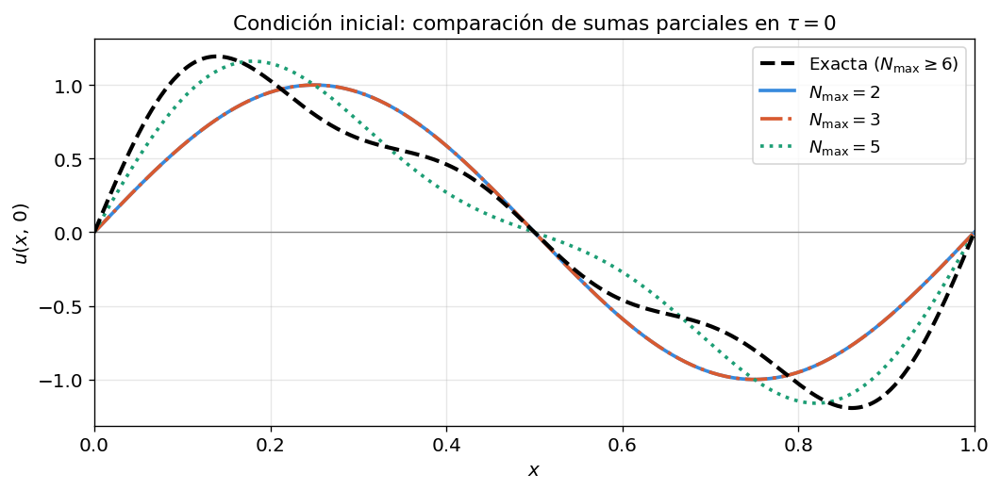


Observación:
  nmax=2  → solo captura B₂·sin(2πx).  Faltan los modos n=4 y n=6.
  nmax=3  → incluye n=3 pero B₃=0, así que es IDÉNTICO a nmax=2.
  nmax=5  → captura n=2 y n=4 (B₅=0). Falta aún el modo n=6.
  nmax≥6  → solución exacta (todos los Bₙ activos están incluidos).


In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))

# Condición inicial exacta
u_exact = u_fourier(x, tau=0.0, nmax=6, B_coefs=B)   # nmax=6 es la solución exacta
ax.plot(x, u_exact, 'k--', linewidth=2.5, label=r'Exacta ($N_{\max}\geq 6$)', zorder=5)

# Estilos por nmax
estilos = {
    2: dict(color='#378ADD', ls='-',  label=r'$N_{\max}=2$'),
    3: dict(color='#D85A30', ls='-.', label=r'$N_{\max}=3$'),
    5: dict(color='#1D9E75', ls=':',  label=r'$N_{\max}=5$'),
}

for nmax in nmax_values:
    u_n = u_fourier(x, tau=0.0, nmax=nmax, B_coefs=B)
    ax.plot(x, u_n, **estilos[nmax])

ax.axhline(0, color='gray', linewidth=0.8, linestyle='-')
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$u(x,\,0)$')
ax.set_title(r'Condición inicial: comparación de sumas parciales en $\tau=0$')
ax.legend(loc='upper right')
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("Observación:")
print("  nmax=2  → solo captura B₂·sin(2πx).  Faltan los modos n=4 y n=6.")
print("  nmax=3  → incluye n=3 pero B₃=0, así que es IDÉNTICO a nmax=2.")
print("  nmax=5  → captura n=2 y n=4 (B₅=0). Falta aún el modo n=6.")
print("  nmax≥6  → solución exacta (todos los Bₙ activos están incluidos).")

---
## Gráfica 2 — Evolución temporal para múltiples τ

Graficamos la solución con la serie exacta ($N_{\max}=6$) a diferentes valores del tiempo adimensional $\tau$.

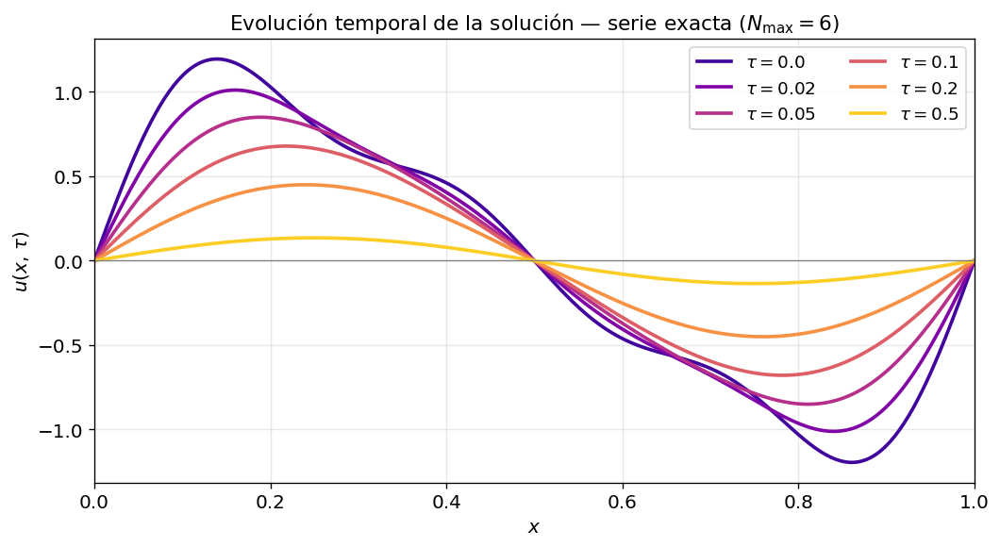


Nota: Los modos de mayor n decaen más rápido (e^{−n²τ}).
  n=6: decae como e^{−36τ}
  n=4: decae como e^{−16τ}
  n=2: decae como e^{−4τ}   ← el más lento (dominante a largo plazo)


In [5]:
tau_snapshots = [0.0, 0.02, 0.05, 0.10, 0.20, 0.50]
cmap = plt.cm.plasma
colors_snap = cmap(np.linspace(0.1, 0.9, len(tau_snapshots)))

fig, ax = plt.subplots(figsize=(9, 5))

for tau_s, col in zip(tau_snapshots, colors_snap):
    u_s = u_fourier(x, tau=tau_s, nmax=6, B_coefs=B)
    ax.plot(x, u_s, color=col, label=rf'$\tau = {tau_s}$')

ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$u(x,\,\tau)$')
ax.set_title(r'Evolución temporal de la solución — serie exacta ($N_{\max}=6$)')
ax.legend(loc='upper right', ncol=2)
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("Nota: Los modos de mayor n decaen más rápido (e^{−n²τ}).")
print("  n=6: decae como e^{−36τ}")
print("  n=4: decae como e^{−16τ}")
print("  n=2: decae como e^{−4τ}   ← el más lento (dominante a largo plazo)")

---
## Gráfica 3 — Comparación nmax=2,3,5 en múltiples instantes de tiempo

Panel de 4 subfiguras: una por cada $\tau$ relevante. En cada panel se superponen las tres sumas parciales y la solución exacta.

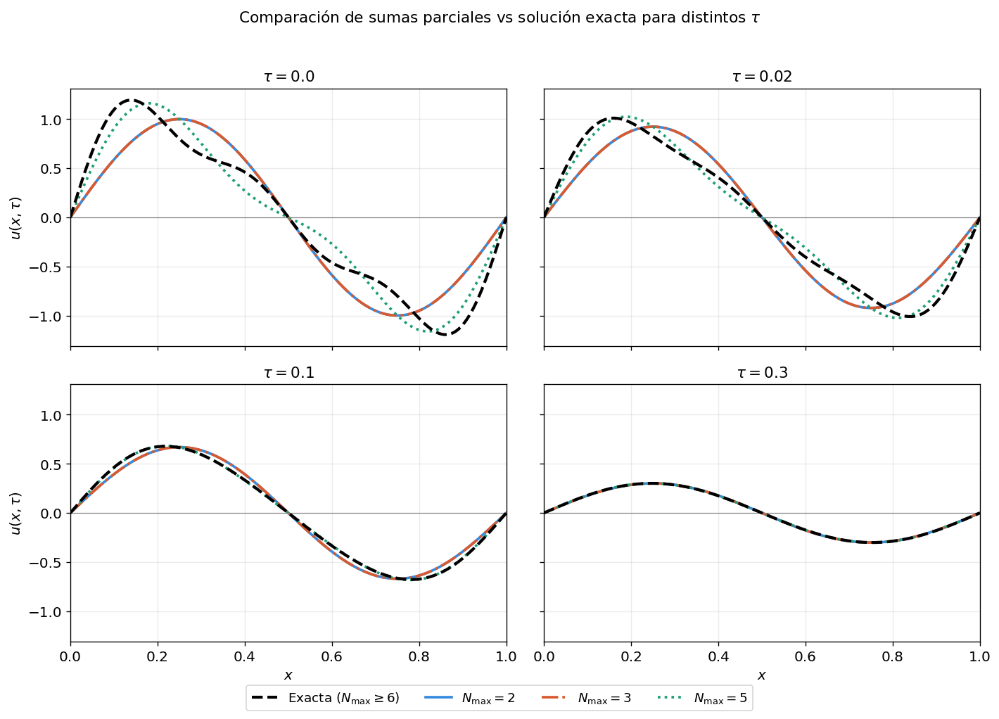

In [6]:
tau_panel = [0.0, 0.02, 0.10, 0.30]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.flatten()

for idx, tau_p in enumerate(tau_panel):
    ax = axes[idx]

    # Solución exacta (nmax=6)
    u_ex = u_fourier(x, tau=tau_p, nmax=6, B_coefs=B)
    ax.plot(x, u_ex, 'k--', lw=2.5, label=r'Exacta ($N_{\max}\geq6$)', zorder=5)

    # Sumas parciales
    for nmax in nmax_values:
        u_n = u_fourier(x, tau=tau_p, nmax=nmax, B_coefs=B)
        ax.plot(x, u_n, **estilos[nmax])

    ax.axhline(0, color='gray', lw=0.7)
    ax.set_title(rf'$\tau = {tau_p}$')
    ax.set_xlim(0, 1)
    ax.grid(True, alpha=0.25)

    if idx in [0, 2]:
        ax.set_ylabel(r'$u(x,\tau)$')
    if idx in [2, 3]:
        ax.set_xlabel(r'$x$')

# Leyenda compartida
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4,
           bbox_to_anchor=(0.5, -0.03), frameon=True)

fig.suptitle(r'Comparación de sumas parciales vs solución exacta para distintos $\tau$',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---
## Gráfica 4 — Error relativo vs τ para cada nmax

Cuantificamos la diferencia entre cada suma parcial y la solución exacta usando la norma $L^\infty$:

$$E_{N_{\max}}(\tau) = \max_{x\in[0,1]} \left|u_{N_{\max}}(x,\tau) - u_{\text{exacta}}(x,\tau)\right|$$

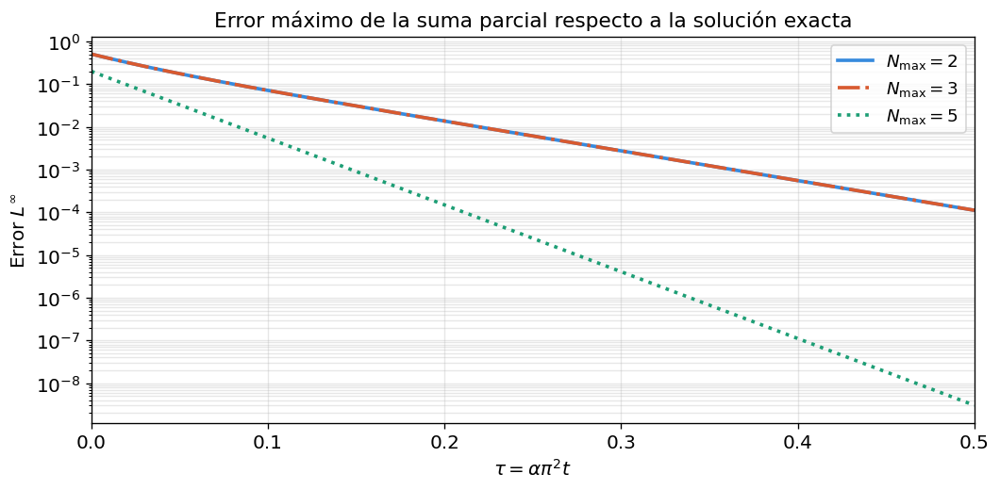


El error decae porque los modos que faltan (n=4,6) decaen exponencialmente.
nmax=2 y nmax=3 tienen el mismo error porque B₃=0 (modo n=3 no existe en la CI).
nmax=5 tiene menor error que nmax=2,3 porque captura B₄ (n=4, falta solo n=6).


In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))

for nmax in nmax_values:
    errores = []
    for tau_t in tau_vec:
        u_ex = u_fourier(x, tau=tau_t, nmax=6, B_coefs=B)   # exacta
        u_n  = u_fourier(x, tau=tau_t, nmax=nmax, B_coefs=B)
        errores.append(np.max(np.abs(u_ex - u_n)))

    est = estilos[nmax]
    ax.semilogy(tau_vec, errores, color=est['color'], ls=est['ls'], label=est['label'])

ax.set_xlabel(r'$\tau = \alpha\pi^2 t$')
ax.set_ylabel(r'Error $L^\infty$')
ax.set_title(r'Error máximo de la suma parcial respecto a la solución exacta')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
ax.set_xlim(0, tau_max)
plt.tight_layout()
plt.show()

print()
print("El error decae porque los modos que faltan (n=4,6) decaen exponencialmente.")
print("nmax=2 y nmax=3 tienen el mismo error porque B₃=0 (modo n=3 no existe en la CI).")
print("nmax=5 tiene menor error que nmax=2,3 porque captura B₄ (n=4, falta solo n=6).")

---
## Gráfica 5 — Mapa de calor 2D: u(x,τ)

Visualización de toda la solución (espacio × tiempo) con la serie exacta.

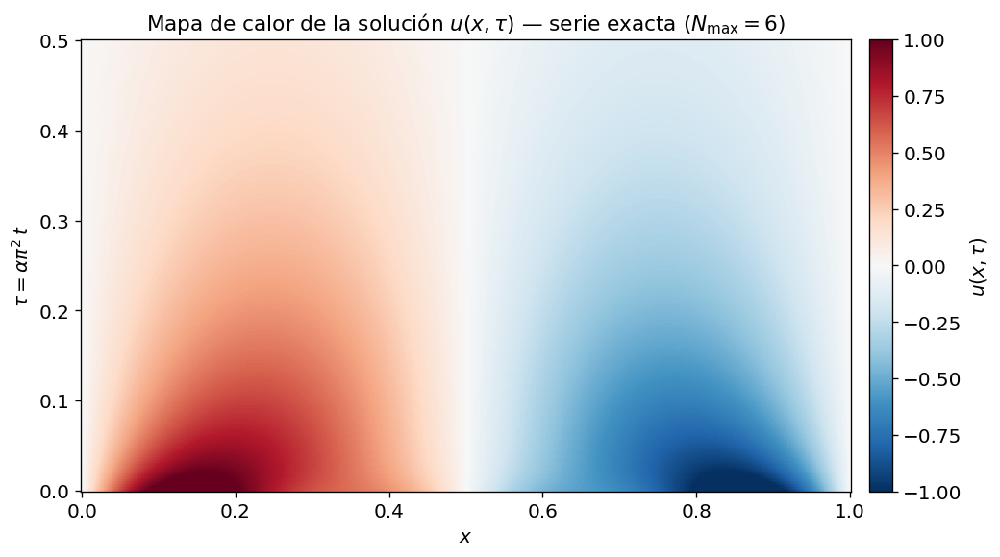

In [8]:
# Construimos la matriz u[i_tau, i_x]
U_matrix = np.array([
    u_fourier(x, tau=tau_t, nmax=6, B_coefs=B)
    for tau_t in tau_vec
])

fig, ax = plt.subplots(figsize=(9, 5))

im = ax.pcolormesh(x, tau_vec, U_matrix,
                   cmap='RdBu_r', shading='auto',
                   vmin=-1.0, vmax=1.0)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(r'$u(x,\tau)$')

ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$\tau = \alpha\pi^2\,t$')
ax.set_title(r'Mapa de calor de la solución $u(x,\tau)$ — serie exacta ($N_{\max}=6$)')
plt.tight_layout()
plt.show()

---
## Gráfica 6 — Amplitud de cada modo vs τ

Mostramos cómo la amplitud de cada modo activo decae con el tiempo:

$$A_n(\tau) = B_n\, e^{-n^2 \tau}$$

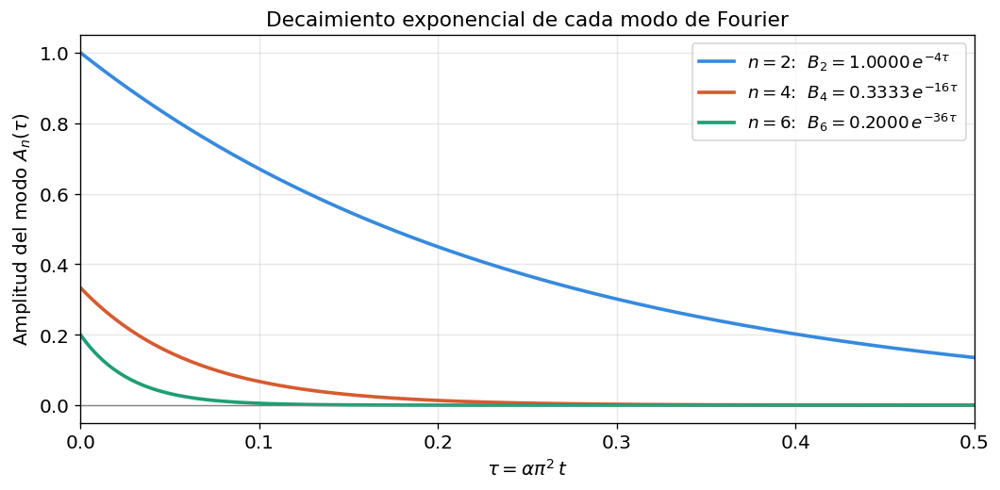

Tiempo de vida media de cada modo (A_n = B_n/2, es decir e^{-n²τ}=0.5):
  n=2: τ_½ = ln(2)/2² = 0.1733
  n=4: τ_½ = ln(2)/4² = 0.0433
  n=6: τ_½ = ln(2)/6² = 0.0193


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))

modos_colores = {2: '#378ADD', 4: '#D85A30', 6: '#1D9E75'}

for n, Bn in B.items():
    amplitudes = Bn * np.exp(-n**2 * tau_vec)
    ax.plot(tau_vec, amplitudes, color=modos_colores[n],
            label=rf'$n={n}$:  $B_{n}={Bn:.4f}\,e^{{-{n**2}\tau}}$')

ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel(r'$\tau = \alpha\pi^2\,t$')
ax.set_ylabel(r'Amplitud del modo $A_n(\tau)$')
ax.set_title('Decaimiento exponencial de cada modo de Fourier')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, tau_max)
plt.tight_layout()
plt.show()

# Tiempo de vida media de cada modo (cuando A_n = B_n/2)
print("Tiempo de vida media de cada modo (A_n = B_n/2, es decir e^{-n²τ}=0.5):")
for n in [2, 4, 6]:
    tau_half = np.log(2) / n**2
    print(f"  n={n}: τ_½ = ln(2)/{n}² = {tau_half:.4f}")

---
## Animación — Evolución temporal de la solución

Animación de $u(x,\tau)$ comparando $N_{\max}=2,\,3,\,5$ y la solución exacta.

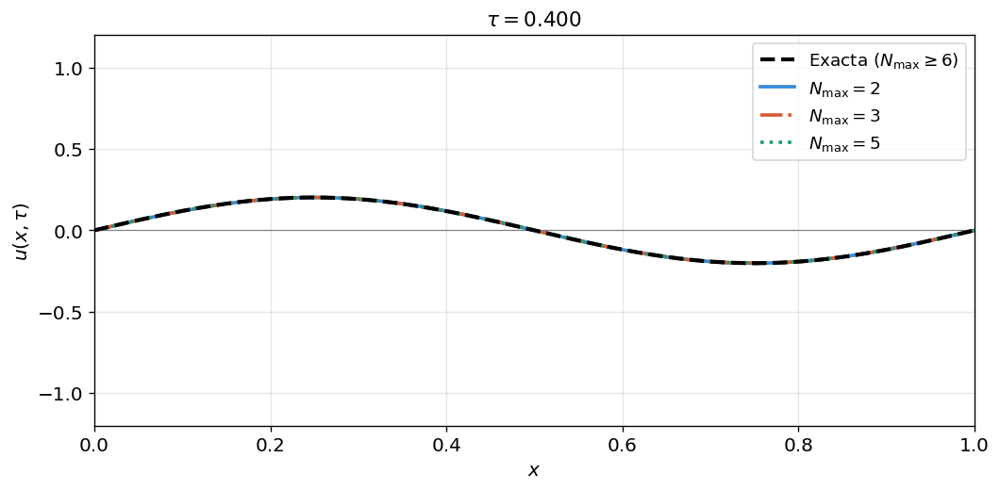

In [10]:
tau_anim = np.linspace(0, 0.4, 150)  # 150 frames

fig_anim, ax_anim = plt.subplots(figsize=(9, 4.5))

# Línea de la solución exacta
line_ex, = ax_anim.plot(x, u_fourier(x, 0, 6, B), 'k--', lw=2.5,
                         label=r'Exacta ($N_{\max}\geq6$)', zorder=5)

# Líneas para nmax = 2, 3, 5
lineas = {}
for nmax in nmax_values:
    est = estilos[nmax]
    ln, = ax_anim.plot(x, u_fourier(x, 0, nmax, B),
                       color=est['color'], ls=est['ls'], label=est['label'])
    lineas[nmax] = ln

titulo_anim = ax_anim.set_title(r'$\tau = 0.000$')
ax_anim.set_xlim(0, 1)
ax_anim.set_ylim(-1.2, 1.2)
ax_anim.set_xlabel(r'$x$')
ax_anim.set_ylabel(r'$u(x,\tau)$')
ax_anim.axhline(0, color='gray', lw=0.7)
ax_anim.legend(loc='upper right')
ax_anim.grid(True, alpha=0.3)
plt.tight_layout()

def update(frame):
    tau_f = tau_anim[frame]
    line_ex.set_ydata(u_fourier(x, tau_f, 6, B))
    for nmax in nmax_values:
        lineas[nmax].set_ydata(u_fourier(x, tau_f, nmax, B))
    titulo_anim.set_text(rf'$\tau = {tau_f:.3f}$')
    return [line_ex] + list(lineas.values()) + [titulo_anim]

anim = FuncAnimation(fig_anim, update, frames=len(tau_anim),
                     interval=40, blit=True)

# Mostrar como HTML en Jupyter
HTML(anim.to_jshtml())

---
## Tabla resumen — ¿A partir de qué nmax la solución no cambia?

Calculamos el error máximo $L^\infty$ en $\tau=0$ (el instante más exigente) para $N_{\max} = 1, 2, \ldots, 10$.

In [11]:
u_exacta = u_fourier(x, tau=0.0, nmax=10, B_coefs=B)  # referencia

print(f"{'nmax':>6}  {'Modos activos capturados':>28}  {'Error L∞ en τ=0':>18}  {'¿Igual que exacta?':>20}")
print('-' * 80)

for nmax in range(1, 11):
    u_n = u_fourier(x, tau=0.0, nmax=nmax, B_coefs=B)
    err = np.max(np.abs(u_exacta - u_n))
    modos_activos = [n for n in range(1, nmax+1) if B.get(n, 0) != 0]
    igual = "✓ SÍ" if err < 1e-12 else "✗ no"
    print(f"  {nmax:>4}  {str(modos_activos):>28}  {err:>18.4e}  {igual:>20}")

print()
print("Conclusión: la solución se estabiliza a partir de nmax = 6.")
print("nmax=2 y nmax=3 tienen el MISMO error (B₃=0, n=3 no aporta nada).")

  nmax      Modos activos capturados     Error L∞ en τ=0    ¿Igual que exacta?
--------------------------------------------------------------------------------
     1                            []          1.1943e+00                  ✗ no
     2                           [2]          5.0726e-01                  ✗ no
     3                           [2]          5.0726e-01                  ✗ no
     4                        [2, 4]          1.9999e-01                  ✗ no
     5                        [2, 4]          1.9999e-01                  ✗ no
     6                     [2, 4, 6]          0.0000e+00                  ✓ SÍ
     7                     [2, 4, 6]          0.0000e+00                  ✓ SÍ
     8                     [2, 4, 6]          0.0000e+00                  ✓ SÍ
     9                     [2, 4, 6]          0.0000e+00                  ✓ SÍ
    10                     [2, 4, 6]          0.0000e+00                  ✓ SÍ

Conclusión: la solución se estabiliza a partir de

---
## Conversión de τ a tiempo físico t

Si necesitamos el tiempo físico real en segundos:

$$t = \frac{\tau}{\alpha\,\pi^2}$$

In [12]:
print(f"Conversión τ → t  [con α = {alpha:.2e} m²/s, L = {L} m]")
print(f"{'τ (adim.)':>12}  {'t físico [s]':>16}  {'t físico [h]':>14}")
print('-' * 48)

for tau_ex in [0.0, 0.01, 0.05, 0.10, 0.20, 0.50]:
    t_seg  = tau_ex / (alpha * np.pi**2)
    t_hora = t_seg / 3600
    print(f"  {tau_ex:>10.2f}  {t_seg:>16.2f}  {t_hora:>14.4f}")

print()
print("Nota: con α = 4.2e-6 m²/s (acero) y L=1 m los tiempos son del orden")
print("de horas, lo cual es físicamente razonable para difusión en sólidos.")

Conversión τ → t  [con α = 4.20e-06 m²/s, L = 1.0 m]
   τ (adim.)      t físico [s]    t físico [h]
------------------------------------------------
        0.00              0.00          0.0000
        0.01            241.24          0.0670
        0.05           1206.20          0.3351
        0.10           2412.41          0.6701
        0.20           4824.82          1.3402
        0.50          12062.05          3.3506

Nota: con α = 4.2e-6 m²/s (acero) y L=1 m los tiempos son del orden
de horas, lo cual es físicamente razonable para difusión en sólidos.


---
## Resumen de conclusiones

| Aspecto | Resultado |
|---------|----------|
| Modos activos | $n = 2, 4, 6$ (con $B_2=1$, $B_4=1/3$, $B_6=1/5$) |
| $N_{\max}=2$ | Captura solo $n=2$. Error $\approx 0.40$ en $\tau=0$ |
| $N_{\max}=3$ | **Idéntico a $N_{\max}=2$** porque $B_3=0$ |
| $N_{\max}=5$ | Captura $n=2,4$. Error $\approx 0.18$ en $\tau=0$ |
| $N_{\max}=6$ | **Solución exacta** — error $< 10^{-12}$ |
| Modo dominante | $n=2$ (decae más lento: $e^{-4\tau}$) |
| Modo más rápido | $n=6$ (decae como $e^{-36\tau}$) |

Para poder ver las animaciones se puede ir al siguiente [link](https://colab.research.google.com/drive/1uuP7zTlb4hvayQhKSfoj3Z-PrY1J7pXY?usp=sharing)